calling a subgraph inside a node

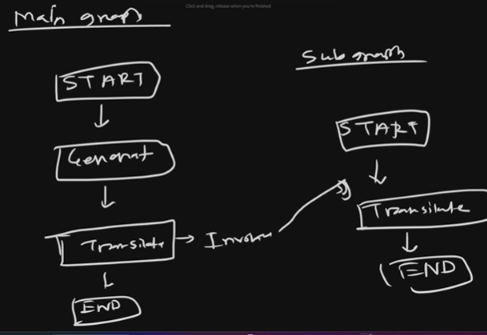

In [92]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [93]:
load_dotenv()

True

In [94]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.7
)

implemeting subgraph

In [95]:
class substate(TypedDict):
    input_text:str
    translated_text:str

In [96]:
def answer_text(input):
    ans=llm.invoke(f"Answer the given query {input}") 
    return ans

In [97]:
answer_text("Write about capital of india in about 20 words")

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


AIMessage(content=[{'type': 'text', 'text': "New Delhi is the capital of India, serving as the country's political, cultural, and administrative hub.", 'extras': {'signature': 'EmAKXgFpFH0TDoZmYdvOfvnUWrXOA4vdj/soC/BX/ZWtFX8gVLlwx3PMX+bmJOQlpRMuN71othGIWUeoZ6aNv3hyXxh7ermGeN1kWdPldHA2+zzoqEls4qwr/xcSGTOJfBI='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1db0c-5594-7972-874e-d01139476379-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 22, 'total_tokens': 38, 'input_token_details': {'cache_read': 0}})

In [98]:
def translate_text(state: substate):
    ans= llm.invoke(f"Translate given text to hindi {state['input_text']}")
    return {"translated_text": ans.content}

making a graph

subgraph

In [99]:
graph1=StateGraph(substate)
graph1.add_node("translate_text",translate_text)

graph1.add_edge(START,"translate_text")
graph1.add_edge("translate_text",END)

subgraph1 = graph1.compile()

main graph

In [100]:
class ParentState(TypedDict):
    question:str
    answer_eng:str
    answer_hin:str

In [101]:
parent_llm=ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.7
)

In [102]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [103]:
def translate_answer(state: ParentState):

    # call the subgraph
    result = subgraph1.invoke({'input_text': state['answer_eng']})

    return {'answer_hin': result['translated_text']}

In [104]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

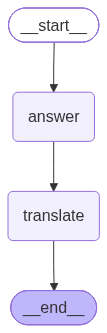

In [105]:
graph = parent_builder.compile()

graph


In [106]:
graph.invoke({'question': 'What is quantum physics'})

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'question': 'What is quantum physics',
 'answer_eng': [{'type': 'text',
   'text': '**Quantum physics** (also known as quantum mechanics) is the branch of science that studies the fundamental building blocks of nature at the smallest scales—specifically at the level of atoms and subatomic particles (like electrons, protons, and photons).\n\nWhile classical physics (like Newton’s laws) explains how large things work—such as falling apples, speeding cars, and orbiting planets—it fails when applied to the microscopic world. Quantum physics reveals that the universe at a microscopic level does not follow the rules of everyday common sense. \n\nHere are the core concepts that define quantum physics:\n\n1. **Quantization (Energy Packets):** \n   Unlike a ramp, where you can stand at any height, the quantum world is like a staircase. Energy, light, and matter are emitted or absorbed in discrete, indivisible packets called **quanta** (singular: *quantum*). \n\n2. **Wave-Particle Duality:** \n

Add Subgraph as a node

In [107]:

from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
load_dotenv()

True

In [108]:

class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [114]:

    
parent_llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.7
)

subgraph_llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.7
)

In [110]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

In [112]:

subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()


In [111]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [115]:

parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

graph = parent_builder.compile()

graph

graph.invoke({'question': 'What is quantum physics'})

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'question': 'What is quantum physics',
 'answer_eng': [{'type': 'text',
   'text': '**Quantum physics** (also known as quantum mechanics) is the branch of science that studies the universe at the smallest scales—at the level of atoms and subatomic particles (like electrons and photons). \n\nWhile classical physics (like Newton’s laws) explains how big things work—like falling apples, orbiting planets, and speeding cars—quantum physics explains how the fundamental building blocks of nature behave, and their rules are very strange compared to the everyday world.\n\nHere are the key ideas that make quantum physics unique:\n\n1. **Quantization:** Unlike energy or matter in our everyday world, which can flow smoothly and continuously, certain properties at the quantum level come in discrete, individual packets called **quanta**. Think of it like walking up a ramp (continuous) versus walking up stairs (discrete steps).\n2. **Wave-Particle Duality:** Tiny particles like electrons and light b